## Setup

In [25]:
import io
import zipfile
import requests
import pandas as pd
import os

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

GENES = {
    "ROR1":  "ENSG00000185483",
    "EGFR":  "ENSG00000146648",
    "ERBB2": "ENSG00000141736",  # HER2
    "EPCAM": "ENSG00000119888",
}
GENE_SYMBOLS = set(GENES.keys())
ENSG_TO_SYMBOL = {v: k for k, v in GENES.items()}
HEADERS = {"User-Agent": "Mozilla/5.0 (research script; contact: you@example.com)"}

In [26]:
os.environ["RPY2_CFFI_MODE"] = "ABI"   # wheel built for R 4.5, we have 4.6

In [27]:
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


In [28]:

%%R
library(tidyverse)
library(patchwork)

dir.create("data/raw", showWarnings = FALSE, recursive = TRUE)
dir.create("data/reference", showWarnings = FALSE, recursive = TRUE)
dir.create("output", showWarnings = FALSE, recursive = TRUE)

targets <- c("ROR1", "EGFR", "ERBB2", "EPCAM")

In [29]:
%%R
# ============================================
# Download + Provenienz (HPA release, SHA256)
# ============================================

dvp_url <- "https://www.proteinatlas.org/download/tsv/dvp_cell_type_group_data.tsv.zip"
zip_path <- "data/raw/dvp_cell_type_group_data.tsv.zip"
tsv_path <- "data/raw/dvp_cell_type_group_data.tsv"

if (!file.exists(tsv_path)) {
download.file(dvp_url, zip_path, mode = "wb")
unzip(zip_path, exdir = "data/raw")
}

sha256 <- digest::digest(file = tsv_path, algo = "sha256")

data_manifest <- tibble(
    source = "Human Protein Atlas - Deep Visual Proteomics",
    HPA_release = "25.1",   # manuell verifizieren auf proteinatlas.org/about/download
    download_date = as.character(Sys.Date()),
filename = basename(tsv_path),
SHA256 = sha256,
n_rows = NA_integer_,   # wird nach dem Einlesen ergänzt
n_cell_types = NA_integer_
)

cat("SHA256:", sha256, "\n")

SHA256: 4966ba76c83582e52caa48aa6e8261931dc10d0b955eb13af34f065b4eb82ca3 


In [30]:
%%R
# ============================================
# 1. Select targets
# ============================================

dvp <- readr::read_tsv(tsv_path, show_col_types = FALSE)

x <- dvp %>%
filter(`Gene name` %in% targets) %>%
select(
    gene = `Gene name`,
cell_type = `Cell type name`,
intensity = Intensity
)

# Hard QC
stopifnot(setequal(unique(x$gene), targets))

# One value per gene × cell-type group expected
dup <- x %>% count(gene, cell_type) %>% filter(n != 1)
stopifnot(nrow(dup) == 0)

# Expect 24 HPA-DVP cell-type groups
stopifnot(n_distinct(x$cell_type) == 24)

cat("Gene:", n_distinct(x$gene), "| Cell-type groups:", n_distinct(x$cell_type), "| Zeilen:", nrow(x), "\n")

Gene: 4 | Cell-type groups: 24 | Zeilen: 96 


In [31]:
%%R
# ============================================
# Zelltyp-Metadaten: EINMALIG anlegen (ersetzt hartkodierten Python-Dict)
# ============================================

cell_type_metadata <- tibble::tribble(
    ~cell_type,                   ~cell_type_class,    ~source_tissue,      ~display_group,     ~display_order,
    "b-cells",                     "Immune",            "blood",             "Blood / Immune",   1,
    "t-cells",                     "Immune",            "blood",             "Blood / Immune",   2,
    "macrophages",                 "Immune",            "blood",             "Blood / Immune",   3,
    "neutrophils",                 "Immune",            "blood",             "Blood / Immune",   4,
    "neurons",                     "Neural",            "brain",             "Brain",            5,
    "astrocytes and neuropil",     "Neural",            "brain",             "Brain",            6,
    "microglia and neuropil",      "Neural",            "brain",             "Brain",            7,
    "cardiomyocytes",              "Muscle",            "heart muscle",      "Heart",            8,
    "capillaries",                 "Endothelial",       "heart muscle",      "Heart",            9,
    "glomeruli",                   "Epithelial",        "kidney",            "Kidney",           10,
    "proximal tubules",            "Epithelial",        "kidney",            "Kidney",           11,
    "distal tubules",              "Epithelial",        "kidney",            "Kidney",           12,
    "collecting ducts",            "Epithelial",        "kidney",            "Kidney",           13,
    "hepatocytes",                 "Epithelial",        "liver",             "Liver",            14,
    "alveolar cell types",         "Epithelial",        "lung",              "Lung",             15,
    "granulosa cells",             "Reproductive",      "ovary",             "Ovary",            16,
    "oocytes",                     "Reproductive",      "ovary",             "Ovary",            17,
    "pancreatic islets",           "Epithelial",        "pancreas",          "Pancreas",         18,
    "pancreas epithelial cells",   "Epithelial",        "pancreas",          "Pancreas",         19,
    "large ducts",                 "Epithelial",        "salivary gland",    "Salivary gland",   20,
    "keratinocytes",               "Epithelial",        "skin",              "Skin",             21,
    "skeletal myofibers",          "Muscle",            "skeletal muscle",   "Skeletal muscle",  22,
    "fallopian tube cells",        "Epithelial",        "fallopian tube",    "Fallopian tube",   23,
    "smooth muscle cells",         "Muscle",            "vasculature",       "Vasculature",      24
)

# QC: muss exakt die 24 Zelltypen aus den Daten abdecken, 1:1
stopifnot(setequal(cell_type_metadata$cell_type, unique(x$cell_type)))
stopifnot(nrow(cell_type_metadata) == 24)

write_tsv(cell_type_metadata, "data/reference/HPA_DVP_cell_type_metadata.tsv")
cat("Referenzdatei geschrieben:", nrow(cell_type_metadata), "Zelltypen\n")
print(cell_type_metadata)

Referenzdatei geschrieben: 24 Zelltypen
# A tibble: 24 × 5
   cell_type           cell_type_class source_tissue display_group display_order
   <chr>               <chr>           <chr>         <chr>                 <dbl>
 1 b-cells             Immune          blood         Blood / Immu…             1
 2 t-cells             Immune          blood         Blood / Immu…             2
 3 macrophages         Immune          blood         Blood / Immu…             3
 4 neutrophils         Immune          blood         Blood / Immu…             4
 5 neurons             Neural          brain         Brain                     5
 6 astrocytes and neu… Neural          brain         Brain                     6
 7 microglia and neur… Neural          brain         Brain                     7
 8 cardiomyocytes      Muscle          heart muscle  Heart                     8
 9 capillaries         Endothelial     heart muscle  Heart                     9
10 glomeruli           Epithelial      kidney     

In [32]:
%%R
# ============================================
# 2. Detection and transform (jetzt: sqrt statt log10)
# ============================================

x <- x %>%
mutate(
    detected = !is.na(intensity),
intensity_observed = replace_na(intensity, 0),
transformed = sqrt(intensity_observed)   # war: log10(1 + intensity_observed)
)

cat("Nicht-detektierte Werte:", sum(!x$detected), "von", nrow(x), "\n")

Nicht-detektierte Werte: 45 von 96 


In [33]:
%%R
x %>%
group_by(gene) %>%
summarise(
    n_detected = sum(detected),
    n_total = n(),
    pct_detected = round(100 * n_detected / n_total, 1)
) %>%
arrange(pct_detected)

# A tibble: 4 × 4
  gene  n_detected n_total pct_detected
  <chr>      <int>   <int>        <dbl>
1 ROR1           6      24         25  
2 EPCAM         11      24         45.8
3 ERBB2         13      24         54.2
4 EGFR          21      24         87.5


In [34]:
%%R
# ============================================
# 3. ONE global scale — kein per-gene max, kein z-score
# ============================================

global_max <- max(x$transformed)   # war: max(x$log_intensity)

x <- x %>%
mutate(abundance_global = transformed / global_max)

stopifnot(
    min(x$abundance_global) >= 0,
max(x$abundance_global) <= 1
)

stopifnot(n_distinct(x$cell_type) == 24)
stopifnot(n_distinct(x$gene) == 4)
stopifnot(nrow(x) == 96)
stopifnot(all(x$abundance_global >= 0 & x$abundance_global <= 1))

data_manifest$n_rows <- nrow(dvp)
data_manifest$n_cell_types <- n_distinct(x$cell_type)
write_tsv(data_manifest, "data_manifest.tsv")

In [35]:
%%R
# ============================================
# 4. Wide matrix
# ============================================

wide <- x %>%
select(cell_type, gene, abundance_global) %>%
pivot_wider(names_from = gene, values_from = abundance_global)

# ============================================
# 5. All six antigen pairs — L_ij,c = min(A_i,c, A_j,c)
# ============================================

pairs <- combn(targets, 2, simplify = FALSE)

local_liability <- map_dfr(pairs, function(p) {
    g1 <- p[1]; g2 <- p[2]
tibble(
    cell_type = wide$cell_type,
antigen_1 = g1,
antigen_2 = g2,
pair = paste(g1, g2, sep = "--"),
local_liability = pmin(wide[[g1]], wide[[g2]])
)
})

stopifnot(n_distinct(local_liability$pair) == 6)
stopifnot(nrow(local_liability) == 6 * 24)

In [36]:
%%R
# ============================================
# 6. Integrated CTLI
# ============================================

ctli <- local_liability %>%
group_by(pair) %>%
summarise(CTLI = sum(local_liability), .groups = "drop") %>%
arrange(CTLI)

stopifnot(nrow(ctli) == 6)

print(ctli)
# Checksums aus dem Dokument zum Abgleich (NICHT hartkodieren, nur zur Kontrolle):
# ROR1-HER2: 2.93 | ROR1-EpCAM: 2.93 | ROR1-EGFR: 3.51
# HER2-EpCAM: 9.69 | EGFR-EpCAM: 10.62 | EGFR-HER2: 11.80

# A tibble: 6 × 2
  pair          CTLI
  <chr>        <dbl>
1 ROR1--EPCAM  0.232
2 ROR1--ERBB2  0.232
3 ROR1--EGFR   0.259
4 ERBB2--EPCAM 1.69 
5 EGFR--ERBB2  2.54 
6 EGFR--EPCAM  3.01 


In [37]:
%%R
# ============================================
# Zelltyp-Metadaten: EINMALIG als feste Referenzdatei anlegen
# ============================================
# WICHTIG: hier die 24 tatsächlichen cell_type-Werte aus x$cell_type eintragen.
# Bekannte Korrekturen laut Dokument:
#  - "large ducts" -> source_tissue = "salivary gland" (NICHT pancreas!)
#  - "capillaries" -> source_tissue = "heart muscle" (NICHT vasculature)
#  - "smooth muscle cells" -> vasculature bleibt korrekt

cat("Tatsächliche 24 Zelltyp-Gruppen in den Daten:\n")
print(sort(unique(x$cell_type)))

Tatsächliche 24 Zelltyp-Gruppen in den Daten:
 [1] "alveolar cell types"       "astrocytes and neuropil"  
 [3] "b-cells"                   "capillaries"              
 [5] "cardiomyocytes"            "collecting ducts"         
 [7] "distal tubules"            "fallopian tube cells"     
 [9] "glomeruli"                 "granulosa cells"          
[11] "hepatocytes"               "keratinocytes"            
[13] "large ducts"               "macrophages"              
[15] "microglia and neuropil"    "neurons"                  
[17] "neutrophils"               "oocytes"                  
[19] "pancreas epithelial cells" "pancreatic islets"        
[21] "proximal tubules"          "skeletal myofibers"       
[23] "smooth muscle cells"       "t-cells"                  


In [38]:
%%R
# ============================================
# Plot-Reihenfolge aus der Referenzdatei ableiten (statt hartkodiertem Dict)
# ============================================

plot_meta <- cell_type_metadata %>%
arrange(display_order)

# x und local_liability bekommen die Sortierung als Faktor-Level
x <- x %>%
left_join(cell_type_metadata, by = "cell_type") %>%
mutate(cell_type = factor(cell_type, levels = plot_meta$cell_type))

local_liability <- local_liability %>%
left_join(cell_type_metadata, by = "cell_type") %>%
mutate(cell_type = factor(cell_type, levels = plot_meta$cell_type))

# Feste Paar-Reihenfolge (3 ROR1-Paare zuerst, wie im Dokument gefordert)
pair_order <- c("EGFR--EPCAM", "EGFR--ERBB2", "ERBB2--EPCAM", "ROR1--EGFR", "ROR1--EPCAM", "ROR1--ERBB2")

local_liability <- local_liability %>%
mutate(pair = factor(pair, levels = rev(pair_order)))  # rev für y-Achsen-Reihenfolge oben->unten

ctli <- ctli %>%
mutate(pair = factor(pair, levels = pair_order))

In [39]:
%%R
# ============================================
# Y-Achsen-Struktur: Organ-Header + eingerückte Zelltypen (wie im alten Notebook)
# ============================================

organ_order <- cell_type_metadata %>%
arrange(display_order) %>%
distinct(display_group) %>%
pull(display_group)

plot_rows <- map_dfr(organ_order, function(organ) {
                                                      members <- cell_type_metadata %>%
                                                  filter(display_group == organ) %>%
arrange(display_order) %>%
pull(cell_type)

bind_rows(
tibble(label = organ, cell_type = NA_character_, is_header = TRUE),
tibble(label = members, cell_type = members, is_header = FALSE)
)
})

plot_rows <- plot_rows %>%
mutate(y_pos = rev(seq_len(n())))

# In x und local_liability die y-Position mappen
x <- x %>% left_join(plot_rows %>% filter(!is_header) %>% select(cell_type, y_pos), by = "cell_type")
local_liability <- local_liability %>% left_join(plot_rows %>% filter(!is_header) %>% select(cell_type, y_pos), by = "cell_type")

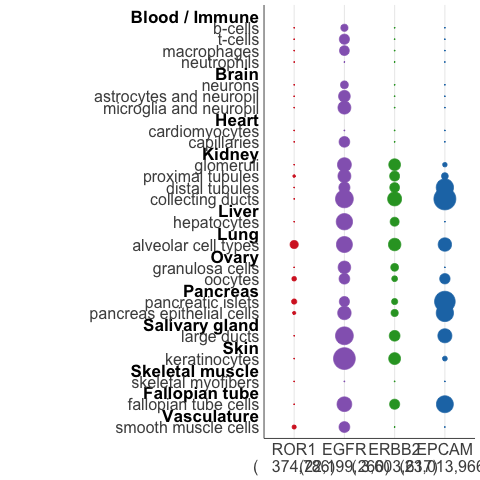

In [40]:
%%R
# ============================================
# Panel a — mit Organ-Headern, exakt wie im Original-Layout
# ============================================

GENE_COLORS <- c(ERBB2 = "#2ca02c", EPCAM = "#1f77b4", EGFR = "#9467bd", ROR1 = "#d62728")

gene_max_labels <- x %>%
group_by(gene) %>%
summarise(max_int = max(intensity_observed, na.rm = TRUE)) %>%
mutate(xlabel = sprintf("%s\n(%s)", gene, format(round(max_int), big.mark = ",")))

panel_a <- x %>%
mutate(gene = factor(gene, levels = c("ROR1", "EGFR", "ERBB2", "EPCAM")))

header_rows <- plot_rows %>% filter(is_header)
celltype_rows <- plot_rows %>% filter(!is_header)

p_a <- ggplot(panel_a, aes(x = gene, y = y_pos, size = abundance_global, colour = gene)) +
geom_point(alpha = 1) +
scale_size_area(max_size = 10, limits = c(0, 1), guide = "none") +
scale_colour_manual(values = GENE_COLORS, guide = "none") +
scale_x_discrete(labels = setNames(gene_max_labels$xlabel, gene_max_labels$gene)) +
scale_y_continuous(
breaks = celltype_rows$y_pos,
labels = celltype_rows$label,
expand = expansion(add = 1)
) +
# Organ-Header links außerhalb des Panels, fett
annotate("text", x = 0.3, y = header_rows$y_pos, label = header_rows$label,
hjust = 1, fontface = "bold", size = 6) +
coord_cartesian(clip = "off", xlim = c(1, 4)) +
labs(x = NULL, y = NULL) +
theme_minimal(base_size = 10) +
theme(
axis.text.y = element_text(hjust = 1, size = 16),
axis.text.x = element_text(size = 16),
panel.grid.minor = element_blank(),
panel.grid.major.y = element_blank(),
plot.margin = margin(l = 90, t = 5, r = 5, b = 5),
panel.border = element_blank(),
axis.line = element_line(color = "grey30")
)

print(p_a)

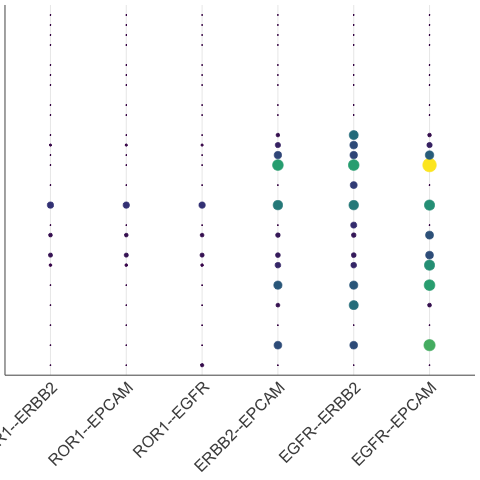

In [41]:
%%R
p_b <- ggplot(local_liability, aes(x = pair, y = y_pos, size = local_liability, colour = local_liability)) +
geom_point() +
scale_size_area(max_size = 6, limits = c(0, max(local_liability$local_liability)), guide = "none") +
scale_colour_viridis_c(limits = c(0, max(local_liability$local_liability)), guide = "none") +
scale_y_continuous(breaks = celltype_rows$y_pos, labels = NULL, expand = expansion(add = 1)) +
labs(x = NULL, y = NULL) +
theme_minimal(base_size = 10) +
theme(
    axis.text.x = element_text(angle = 45, hjust = 1, size = 16),
axis.ticks.y = element_blank(),
panel.grid.minor = element_blank(),
panel.grid.major.y = element_blank(),
panel.border = element_blank(),
axis.line = element_line(color = "grey30")
)

print(p_b)

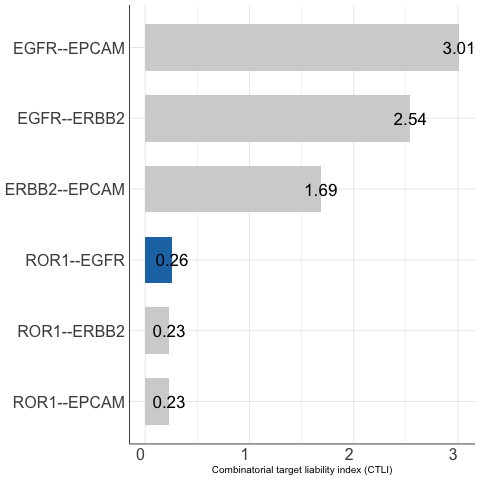

In [42]:
%%R
p_c <- ggplot(ctli, aes(x = CTLI, y = forcats::fct_reorder(pair, CTLI), fill = pair == "ROR1--EGFR")) +
geom_col(width = 0.66) +
geom_text(aes(label = sprintf("%.2f", CTLI)), hjust = 0.5, size = 6) +
scale_fill_manual(values = c(`TRUE` = "#1f77b4", `FALSE` = "lightgrey"), guide = "none") +
labs(x = "Combinatorial target liability index (CTLI)", y = NULL) +
theme_minimal(base_size = 10) +
theme(axis.text.x = element_text(hjust = 1, size = 16),
axis.text.y = element_text(hjust = 1, size = 16),
axis.ticks.y = element_blank(),
axis.line = element_line(color = "grey30")
)

print(p_c)

In [43]:
%%R
# ============================================
# Legende A: Größenlegende (0.25/0.50/0.75/1.00), wie im Original
# ============================================
legend_a_data <- tibble(val = c(0.25, 0.50, 0.75, 1.00), x = 1:4, y = 1)

leg_a <- ggplot(legend_a_data, aes(x = x, y = y, size = val)) +
geom_point(color = "grey40") +
scale_size_area(max_size = 10, limits = c(0, 1)) +
geom_text(aes(label = sprintf("%.2f", val)), vjust = 2.2, size = 16/.pt) +
labs(title = "Protein abundance (global scale, log10)") +
theme_void(base_size = 10) +
theme(legend.position = "none", plot.title = element_text(hjust = 0.5, size = 16)) +
xlim(0.5, 4.5) +
ylim(0.5, 1.5)

# ============================================
# Legende B: Farbskala für Local Liability (ersetzt MM-Score-Colorbar)
# ============================================
leg_b_plot <- ggplot(local_liability, aes(x = cell_type, y = pair, colour = local_liability)) +
geom_point(size = 3) +
scale_colour_viridis_c(limits = c(0, max(local_liability$local_liability))) +
guides(colour = guide_colorbar(
    title = "Local combinatorial liability\n(min-gated, AND-rule)",
    barwidth = 12, barheight = 0.8, title.position = "top", title.hjust = 0.5
)) +
theme_void() +
theme(legend.position = "bottom", legend.title = element_text(size = 16, hjust = 0.5))

leg_b <- cowplot::get_legend(leg_b_plot)

# ============================================
# Legende C: nur ROR1--EGFR hervorgehoben (kein "safest"/"optimal")
# ============================================
#legend_c_data <- tibble(
#    label = c("ROR1–EGFR", "Other combinations"),
#    color = c("#1f77b4", "lightgrey")
#)

#leg_c <- ggplot(legend_c_data, aes(x = 1, y = label, fill = label)) +
#geom_tile(width = 0.3, height = 0.3) +
#scale_fill_manual(values = setNames(legend_c_data$color, legend_c_data$label)) +
#theme_void(base_size = 9) +
#theme(legend.position = "none") +
#geom_text(aes(label = label), hjust = -0.3, size = 6)

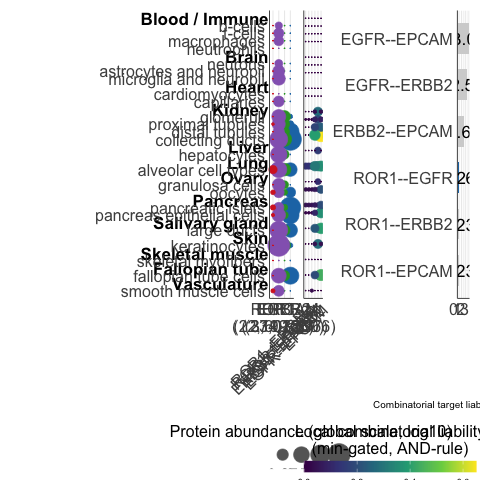

In [44]:
%%R
# ============================================
# Finale Figur — gleiches Layout wie im Original: Hauptpanels oben, Legenden schmal darunter
# ============================================

top_row <- p_a + p_b + p_c + plot_layout(widths = c(1.4, 1.1, 0.7))
legend_row <- leg_a + wrap_elements(leg_b) + plot_layout(widths = c(1.4, 1.1, 0.7))

final_fig5 <- top_row / legend_row + plot_layout(heights = c(20, 2))

print(final_fig5)
ggsave("output/Figure5big.svg", final_fig5, width = 18, height = 14, dpi = 300)

In [45]:
%%R
x %>%
group_by(gene) %>%
summarise(
    mean_abundance = round(mean(abundance_global), 3),
    max_abundance = round(max(abundance_global), 3),
    median_abundance_detected = round(median(abundance_global[detected]), 3),
    n_detected = sum(detected)
) %>%
arrange(desc(mean_abundance))

# A tibble: 4 × 5
  gene  mean_abundance max_abundance median_abundance_detected n_detected
  <chr>          <dbl>         <dbl>                     <dbl>      <int>
1 EGFR           0.312         0.982                     0.314         21
2 EPCAM          0.201         1                         0.397         11
3 ERBB2          0.106         0.396                     0.194         13
4 ROR1           0.011         0.128                     0.031          6


In [46]:
%%R
# ============================================
# Tabelle: Zelltypen (Zeilen) x Gene (Spalten), Protein-Abundanz in den Zellen
# ============================================

wide %>%
  arrange(match(cell_type, plot_meta$cell_type)) %>%
  write_tsv("output/Figure5_panelA_abundance_matrix.tsv")

In [47]:
%%R
x %>%
  select(cell_type, gene, intensity_observed) %>%
  pivot_wider(names_from = gene, values_from = intensity_observed) %>%
  arrange(match(cell_type, plot_meta$cell_type)) %>%
  select(cell_type, ROR1, EGFR, ERBB2, EPCAM) %>%
  print(n = Inf) %>%
  write_tsv("output/Figure5_panelA_abundance_matrix.tsv")

# A tibble: 24 × 5
   cell_type                    ROR1      EGFR    ERBB2     EPCAM
   <chr>                       <dbl>     <dbl>    <dbl>     <dbl>
 1 b-cells                        0    207369.       0         0 
 2 t-cells                        0    913336.       0         0 
 3 macrophages                    0    785353.       0         0 
 4 neutrophils                    0         0        0         0 
 5 neurons                        0    306890.       0         0 
 6 astrocytes and neuropil        0   1670124.       0         0 
 7 microglia and neuropil         0   2542478.       0         0 
 8 cardiomyocytes                 0         0        0         0 
 9 capillaries                    0   1138988.       0         0 
10 glomeruli                      0   3461840. 1714111.    24588.
11 proximal tubules            1513.  2562961   862591.   157547 
12 distal tubules                 0   1335534.  769456.  8697167.
13 collecting ducts               0   9727258. 3603617. 2